# 03. Exploratory data analysis

Phase 2, tasks 2.3.1 to 2.3.5. A first look at the processed US Embassy dataset: when PM2.5 is high, how it is distributed, how it relates to weather, and whether anything can be said about space. Everything here describes **associations** in observed data. None of it shows what causes high PM2.5.

Inputs: `data/processed/hourly_us_embassy.csv` and `daily_us_embassy.csv` (run `python scripts/download_data.py`, `scripts/clean_data.py`, `scripts/build_dataset.py`) and, for section 4, `data/raw/mendeley_tashkent/all_sensor.csv`. Figures are saved to `reports/figures/`.

Conventions: local time is Asia/Tashkent (UTC+5). Winter means November to February. A daily mean needs at least 18 observed hours. The weather columns (`era5_*`) are ERA5 reanalysis for the grid cell around the station, not station measurements. The data has gaps (about 80% of hours are valid, with a gap of about four months in 2022), so counts below are given next to the statistics. The statistics here are descriptive: tests, effect sizes and intervals belong to the statistical analysis (notebook 04).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "savefig.bbox": "tight"}
)
OFFSET = pd.Timedelta(hours=5)
WINTER = [11, 12, 1, 2]


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    print("saved reports/figures/" + f"{name}.png")


daily = pd.read_csv(
    ROOT / "data" / "processed" / "daily_us_embassy.csv", index_col=0, parse_dates=True
)
hourly = pd.read_csv(
    ROOT / "data" / "processed" / "hourly_us_embassy.csv", index_col=0, parse_dates=True
)
hourly.index = hourly.index.tz_localize(None)  # naive UTC
hourly_local = hourly.copy()
hourly_local.index = hourly_local.index + OFFSET  # local time
pm = daily["pm25_mean"].dropna()
pm_winter = pm[pm.index.month.isin(WINTER)]
print(
    f"daily means: {len(pm)} days ({pm.index.min().date()} to {pm.index.max().date()}), winter days: {len(pm_winter)}"
)
print(f"valid hours: {int(hourly['pm25'].notna().sum())} of {len(hourly)}")

daily means: 1823 days (2018-11-28 to 2025-02-25), winter days: 690
valid hours: 44077 of 54927


## 1. Temporal patterns (2.3.1)

### 1.1 Monthly pattern and year-to-year differences

      days  mean  median   q25   q75
date                                
1      200  58.1    47.9  28.1  76.1
2      159  41.2    38.3  27.4  48.2
3      157  32.5    29.4  23.3  39.6
4      145  25.0    24.1  17.4  31.5
5      135  21.4    21.5  16.6  26.1
6      166  25.5    24.4  18.1  31.4
7      131  29.8    27.4  18.4  36.9
8      135  29.5    26.6  16.2  35.3
9      121  36.0    32.0  22.9  43.0
10     143  41.8    37.5  29.1  52.1
11     151  58.9    50.9  32.4  71.5
12     180  66.4    59.0  37.4  86.6
saved reports/figures/monthly_pattern.png


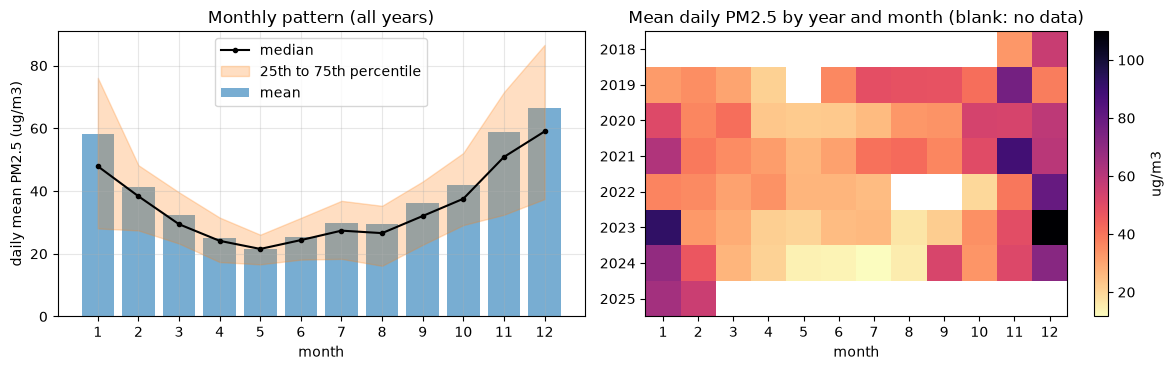

In [2]:
monthly = pm.groupby(pm.index.month).agg(
    days="count",
    mean="mean",
    median="median",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
)
print(monthly.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(monthly.index, monthly["mean"], alpha=0.6, label="mean")
axes[0].plot(monthly.index, monthly["median"], "k.-", label="median")
axes[0].fill_between(
    monthly.index,
    monthly["q25"],
    monthly["q75"],
    color="tab:orange",
    alpha=0.25,
    label="25th to 75th percentile",
)
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("month")
axes[0].set_ylabel("daily mean PM2.5 (ug/m3)")
axes[0].set_title("Monthly pattern (all years)")
axes[0].legend()
table = pm.groupby([pm.index.year, pm.index.month]).mean().unstack()
im = axes[1].imshow(table.to_numpy(), aspect="auto", cmap="magma_r")
axes[1].set_xticks(range(12), range(1, 13))
axes[1].set_yticks(range(len(table)), table.index)
axes[1].set_xlabel("month")
axes[1].set_title("Mean daily PM2.5 by year and month (blank: no data)")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="ug/m3")
plt.tight_layout()
save(fig, "monthly_pattern")

In [3]:
# Number of days behind each cell of the year-month table, so thin months are visible.
pm.groupby([pm.index.year, pm.index.month]).count().unstack().fillna(0).astype(int)

date,1,2,3,4,5,6,7,8,9,10,11,12
date,,,,,,,,,,,,
2018,0,0,0,0,0,0,0,0,0,0,3,20
2019,28,27,29,15,0,26,28,22,20,28,29,30
2020,30,26,29,28,28,27,22,27,27,25,26,26
2021,25,23,28,26,19,25,19,25,29,30,22,30
2022,29,27,28,19,29,28,4,0,0,3,29,24
2023,26,3,12,27,28,30,29,31,30,29,16,22
2024,31,28,31,30,31,30,29,30,15,28,26,28
2025,31,25,0,0,0,0,0,0,0,0,0,0


### 1.2 Daily and weekly cycles

                  hours  night mean (00-06)  afternoon mean (12-16)  evening mean (20-23)
season                                                                                   
winter (Nov-Feb)  16707                62.2                    45.3                  65.6
spring (Mar-Apr)   7271                32.1                    22.4                  34.4
summer (May-Aug)  13688                25.4                    23.4                  33.0
autumn (Sep-Oct)   6411                40.9                    29.7                  47.8
saved reports/figures/daily_and_weekly_cycles.png

     all days  winter days
Mon      41.7         58.0
Tue      40.5         55.2
Wed      41.1         58.3
Thu      39.8         56.2
Fri      39.0         54.0
Sat      39.3         58.7
Sun      39.3         55.3


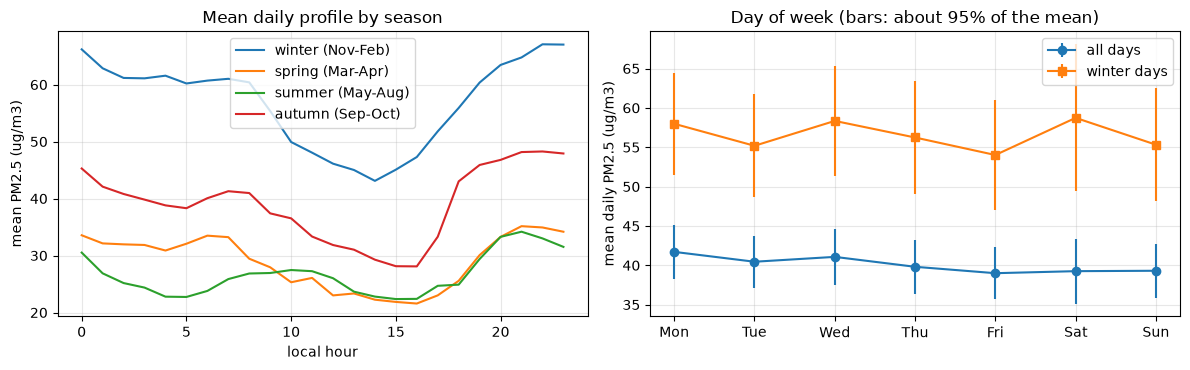

In [4]:
seasons = {
    "winter (Nov-Feb)": [11, 12, 1, 2],
    "spring (Mar-Apr)": [3, 4],
    "summer (May-Aug)": [5, 6, 7, 8],
    "autumn (Sep-Oct)": [9, 10],
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rows = []
for name, months in seasons.items():
    sel = hourly_local[hourly_local.index.month.isin(months)]["pm25"].dropna()
    by_hour = sel.groupby(sel.index.hour)
    axes[0].plot(by_hour.mean(), label=name)
    rows.append(
        {
            "season": name,
            "hours": len(sel),
            "night mean (00-06)": sel[sel.index.hour < 6].mean(),
            "afternoon mean (12-16)": sel[
                (sel.index.hour >= 12) & (sel.index.hour <= 16)
            ].mean(),
            "evening mean (20-23)": sel[sel.index.hour >= 20].mean(),
        }
    )
axes[0].set_xlabel("local hour")
axes[0].set_ylabel("mean PM2.5 (ug/m3)")
axes[0].set_title("Mean daily profile by season")
axes[0].legend()
print(pd.DataFrame(rows).set_index("season").round(1).to_string())

weekday = pm.groupby(pm.index.day_of_week).agg(["count", "mean", "sem"])
weekday_w = pm_winter.groupby(pm_winter.index.day_of_week).agg(["count", "mean", "sem"])
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[1].errorbar(
    range(7), weekday["mean"], yerr=1.96 * weekday["sem"], fmt="o-", label="all days"
)
axes[1].errorbar(
    range(7),
    weekday_w["mean"],
    yerr=1.96 * weekday_w["sem"],
    fmt="s-",
    label="winter days",
)
axes[1].set_xticks(range(7), days)
axes[1].set_ylabel("mean daily PM2.5 (ug/m3)")
axes[1].set_title("Day of week (bars: about 95% of the mean)")
axes[1].legend()
plt.tight_layout()
save(fig, "daily_and_weekly_cycles")
print()
print(
    pd.concat(
        {
            "all days": weekday["mean"].round(1),
            "winter days": weekday_w["mean"].round(1),
        },
        axis=1,
    )
    .set_axis(days)
    .to_string()
)

### 1.3 Seasonal pattern and year-to-year change

A simple additive decomposition of the daily means: the seasonal part is the day-of-year average smoothed over 31 days (circular), and the remainder (the anomaly) is the daily mean minus that seasonal part. Smoothing the anomaly over 90 days shows year-to-year shifts. It is a descriptive decomposition, not a fitted model, and the gaps in the data affect it.

saved reports/figures/seasonal_decomposition.png


,days,mean,median,p90,share of days >= 55.5
2018-19,78,39.29,35.74,66.51,0.22
2019-20,115,50.80,42.17,96.20,0.29
2020-21,100,53.64,50.96,88.93,0.44
2021-22,108,53.54,44.90,87.95,0.33
2022-23,82,67.75,51.22,151.87,0.49
2023-24,97,68.56,58.25,118.67,0.55
2024-25,110,61.46,54.00,104.90,0.47


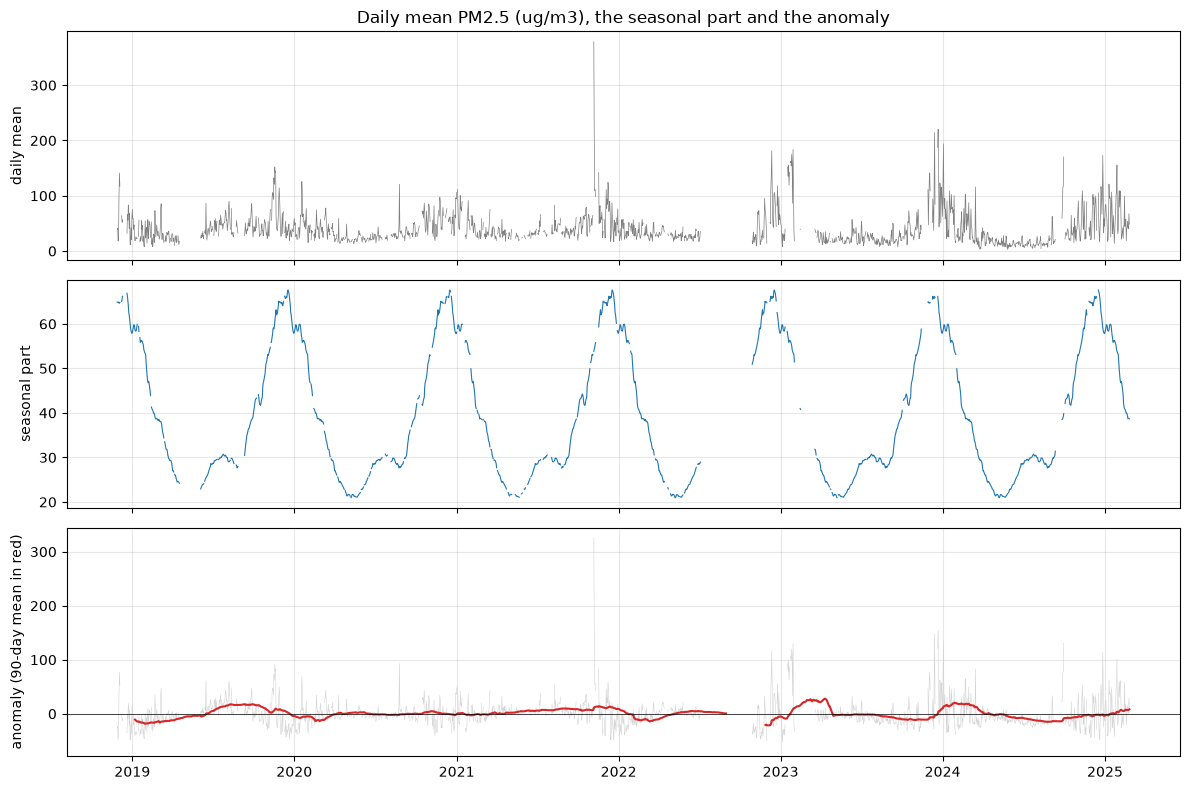

In [5]:
doy = pm.groupby(pm.index.day_of_year).mean().reindex(range(1, 367))
smooth = (
    pd.concat([doy.iloc[-15:], doy, doy.iloc[:15]])
    .rolling(31, center=True, min_periods=15)
    .mean()
    .iloc[15:-15]
)
smooth.index = range(1, 367)
seasonal = pd.Series(smooth.reindex(pm.index.day_of_year).to_numpy(), index=pm.index)
anomaly = pm - seasonal

grid = pd.date_range(
    pm.index.min(), pm.index.max(), freq="D"
)  # missing days show as breaks
pm_g, seasonal_g, anomaly_g = (
    pm.reindex(grid),
    seasonal.reindex(grid),
    anomaly.reindex(grid),
)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(pm_g.index, pm_g, lw=0.5, color="grey")
axes[0].set_ylabel("daily mean")
axes[0].set_title("Daily mean PM2.5 (ug/m3), the seasonal part and the anomaly")
axes[1].plot(seasonal_g.index, seasonal_g, color="tab:blue", lw=0.8)
axes[1].set_ylabel("seasonal part")
axes[2].plot(anomaly_g.index, anomaly_g, lw=0.4, color="lightgrey")
axes[2].plot(anomaly_g.rolling(90, min_periods=30).mean(), color="tab:red")
axes[2].axhline(0, color="k", lw=0.5)
axes[2].set_ylabel("anomaly (90-day mean in red)")
plt.tight_layout()
save(fig, "seasonal_decomposition")

winters = pd.DataFrame(
    {
        "mean": pm_winter,
        "season": np.where(
            pm_winter.index.month >= 11, pm_winter.index.year, pm_winter.index.year - 1
        ),
    }
)
by_winter = winters.groupby("season")["mean"].agg(
    days="count", mean="mean", median="median", p90=lambda x: x.quantile(0.9)
)
by_winter["share of days >= 55.5"] = winters.groupby("season")["mean"].apply(
    lambda x: (x >= 55.5).mean()
)
by_winter.index = [f"{y}-{str(y + 1)[2:]}" for y in by_winter.index]
by_winter.round(2)

In [6]:
share = pm.groupby(pm.index.month).apply(
    lambda x: pd.Series(
        {
            "days": len(x),
            ">= 35.5": (x >= 35.5).mean(),
            ">= 55.5": (x >= 55.5).mean(),
            ">= 100": (x >= 100).mean(),
        }
    )
)
share.round(2)

date         
1     days       200.00
      >= 35.5      0.68
      >= 55.5      0.40
      >= 100       0.14
2     days       159.00
      >= 35.5      0.55
      >= 55.5      0.18
      >= 100       0.03
3     days       157.00
      >= 35.5      0.30
      >= 55.5      0.07
      >= 100       0.01
4     days       145.00
      >= 35.5      0.10
      >= 55.5      0.01
      >= 100       0.00
5     days       135.00
      >= 35.5      0.03
      >= 55.5      0.00
      >= 100       0.00
6     days       166.00
      >= 35.5      0.16
      >= 55.5      0.01
      >= 100       0.00
7     days       131.00
      >= 35.5      0.27
      >= 55.5      0.07
      >= 100       0.01
8     days       135.00
      >= 35.5      0.25
      >= 55.5      0.07
      >= 100       0.01
9     days       121.00
      >= 35.5      0.42
      >= 55.5      0.12
      >= 100       0.02
10    days       143.00
      >= 35.5      0.57
      >= 55.5      0.24
      >= 100       0.00
11    days       151.00
  

## 2. Distribution and extremes (2.3.2)

                        n   mean  median    std  skewness  excess kurtosis  skewness of log     p95     p99     max
series                                                                                                             
hourly              44077  40.31   29.00  37.93      4.51            51.50            -0.27  107.00  188.00  978.00
daily mean           1823  40.09   31.83  28.96      2.79            15.42             0.08   98.14  150.94  378.67
daily mean, winter    690  56.55   47.40  36.72      2.20            10.10            -0.04  122.34  181.75  378.67


saved reports/figures/distribution.png


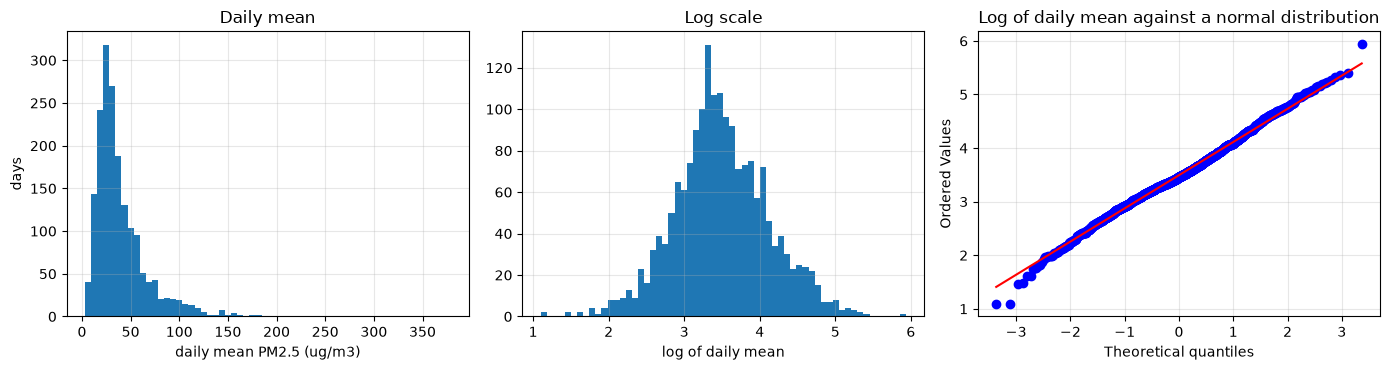

In [7]:
def describe(x, label):
    return {
        "series": label,
        "n": len(x),
        "mean": x.mean(),
        "median": x.median(),
        "std": x.std(),
        "skewness": stats.skew(x),
        "excess kurtosis": stats.kurtosis(x),
        "skewness of log": stats.skew(np.log(x[x > 0])),
        "p95": x.quantile(0.95),
        "p99": x.quantile(0.99),
        "max": x.max(),
    }


hp = hourly["pm25"].dropna()
print(
    pd.DataFrame(
        [
            describe(hp, "hourly"),
            describe(pm, "daily mean"),
            describe(pm_winter, "daily mean, winter"),
        ]
    )
    .set_index("series")
    .round(2)
    .to_string()
)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(pm, bins=60)
axes[0].set_xlabel("daily mean PM2.5 (ug/m3)")
axes[0].set_ylabel("days")
axes[0].set_title("Daily mean")
axes[1].hist(np.log(pm), bins=60)
axes[1].set_xlabel("log of daily mean")
axes[1].set_title("Log scale")
stats.probplot(np.log(pm), dist="norm", plot=axes[2])
axes[2].set_title("Log of daily mean against a normal distribution")
plt.tight_layout()
save(fig, "distribution")

In [8]:
thresholds = {
    "WHO 24 h guideline (15)": 15,
    "EPA moderate and above (35.5)": 35.5,
    "EPA unhealthy for sensitive groups (55.5)": 55.5,
    "100": 100,
    "EPA unhealthy (150.5)": 150.5,
}
exceed = pd.DataFrame(
    {
        "all days": [(pm >= t).mean() for t in thresholds.values()],
        "winter days": [(pm_winter >= t).mean() for t in thresholds.values()],
        "days (all)": [int((pm >= t).sum()) for t in thresholds.values()],
    },
    index=list(thresholds),
)
print("share of days with a daily mean at or above the threshold:")
print(exceed.round(3).to_string())
print()
print(
    "hourly values at or above:",
    {t: int((hp >= t).sum()) for t in (100, 150, 300, 500)},
)

share of days with a daily mean at or above the threshold:
                                           all days  winter days  days (all)
WHO 24 h guideline (15)                       0.907        0.980        1654
EPA moderate and above (35.5)                 0.421        0.688         768
EPA unhealthy for sensitive groups (55.5)     0.196        0.399         357
100                                           0.047        0.116          86
EPA unhealthy (150.5)                         0.010        0.026          19

hourly values at or above: {100: 2668, 150: 907, 300: 82, 500: 12}


### 2.1 High-pollution episodes

An episode is a run of consecutive local days whose daily mean is at least 100 ug/m3 (a day with no daily mean ends a run). 100 is an arbitrary round number between the EPA "unhealthy for sensitive groups" and "unhealthy" bands, used here only to make a list.

In [9]:
high = pm >= 100
full_days = pd.date_range(pm.index.min(), pm.index.max(), freq="D")
series = pm.reindex(full_days)
run_id = ((series >= 100) != (series >= 100).shift()).cumsum()
episodes = []
for _, run in series.groupby(run_id):
    if (run >= 100).all():
        start, end = run.index[0], run.index[-1]
        hours = hourly_local.loc[start : end + pd.Timedelta(hours=23), "pm25"]
        weather = daily.loc[start:end]
        episodes.append(
            {
                "start": start.date(),
                "days": len(run),
                "peak daily mean": run.max(),
                "mean daily": run.mean(),
                "peak hour": hours.max(),
                "mean wind (km/h)": weather["era5_wind_mean"].mean(),
                "mean temp (C)": weather["era5_temp_mean"].mean(),
                "mean boundary layer (m)": weather["era5_blh_mean"].mean(),
            }
        )
episodes = pd.DataFrame(episodes)
print(
    f"{len(episodes)} runs, {int(high.sum())} days at or above 100; {int((episodes['days'] >= 2).sum())} runs last 2 days or more"
)
winter_ref = daily[daily.index.month.isin(WINTER)][
    ["era5_wind_mean", "era5_temp_mean", "era5_blh_mean"]
].mean()
print(
    "winter average wind, temperature, boundary layer height:",
    winter_ref.round(1).to_dict(),
)
episodes[episodes["days"] >= 2].round(1).reset_index(drop=True)

44 runs, 86 days at or above 100; 22 runs last 2 days or more
winter average wind, temperature, boundary layer height: {'era5_wind_mean': 7.2, 'era5_temp_mean': 3.4, 'era5_blh_mean': 146.5}


,start,days,peak daily mean,mean daily,peak hour,mean wind (km/h),mean temp (C),mean boundary layer (m)
0,2018-12-02,3,141.1,120.0,238.0,3.8,0.4,69.4
1,2019-11-13,2,105.7,104.8,163.0,6.2,6.9,122.9
2,2019-11-16,5,152.1,138.4,235.0,5.7,6.9,159.5
3,2020-01-18,2,125.8,116.1,254.0,6.3,-1.9,94.2
4,2021-11-06,4,378.7,201.7,725.0,5.3,3.9,136.6
5,2021-12-08,2,124.4,119.1,164.0,7.0,5.9,108.8
6,2022-12-10,4,181.5,136.6,257.0,4.7,-7.9,42.9
7,2022-12-17,3,106.2,103.1,158.0,4.6,2.1,49.4
8,2023-01-16,6,155.7,141.9,259.0,4.6,-10.0,24.0
9,2023-01-23,5,174.9,161.7,377.0,5.0,-8.8,43.5


saved reports/figures/winters.png


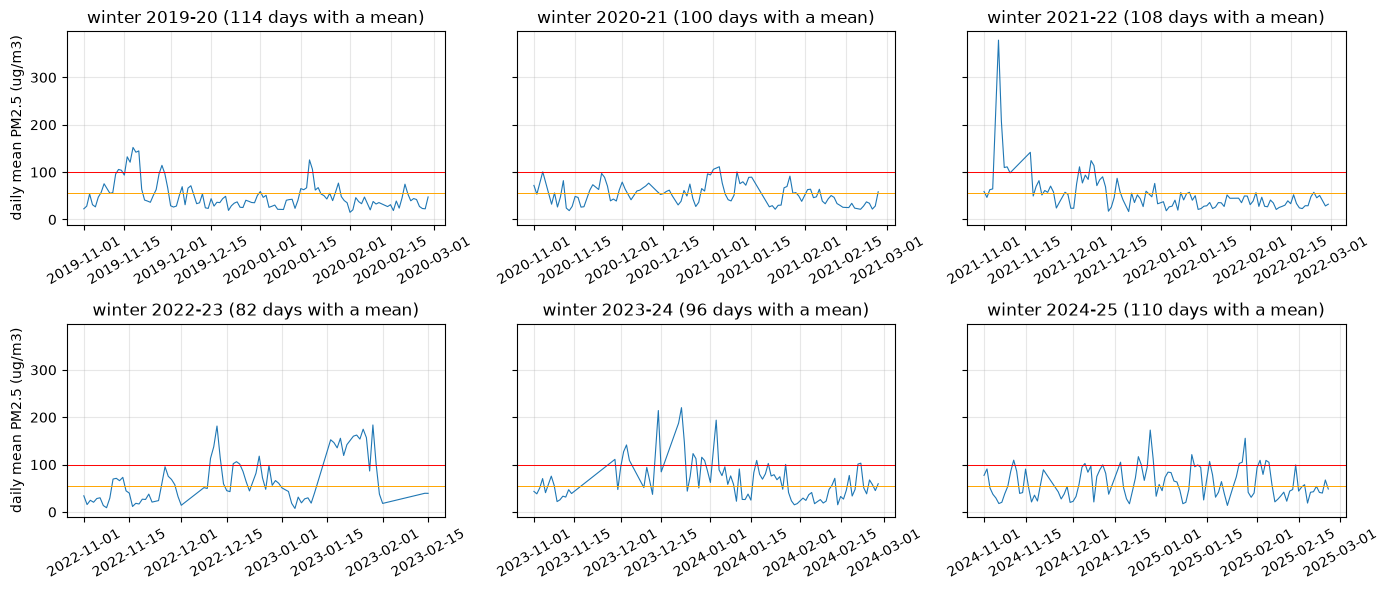

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for ax, season in zip(axes.ravel(), range(2019, 2025), strict=True):
    span = pm[f"{season}-11-01" : f"{season + 1}-02-28"]
    ax.plot(span.index, span, lw=0.8)
    ax.axhline(55.5, color="orange", lw=0.7)
    ax.axhline(100, color="red", lw=0.7)
    ax.set_title(
        f"winter {season}-{str(season + 1)[2:]} ({len(span)} days with a mean)"
    )
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].set_ylabel("daily mean PM2.5 (ug/m3)")
axes[1, 0].set_ylabel("daily mean PM2.5 (ug/m3)")
plt.tight_layout()
save(fig, "winters")

## 3. Relationships with weather (2.3.3)

Spearman correlation of the daily PM2.5 mean with same-day weather
                          winter  all year
temperature                -0.31     -0.44
max temperature            -0.19     -0.40
relative humidity          -0.00      0.21
mean wind speed            -0.56     -0.48
max gust                   -0.57     -0.47
rain, same day             -0.38     -0.14
rain, 3 days               -0.42     -0.11
surface pressure            0.24      0.39
sea-level pressure          0.27      0.42
pressure change            -0.17     -0.13
cloud cover                -0.29      0.00
solar radiation             0.18     -0.37
vapour pressure deficit    -0.12     -0.35
boundary layer (mean)      -0.42     -0.49
boundary layer (min)       -0.47     -0.37
ventilation (BLH x wind)   -0.51     -0.51
saved reports/figures/weather_correlations.png


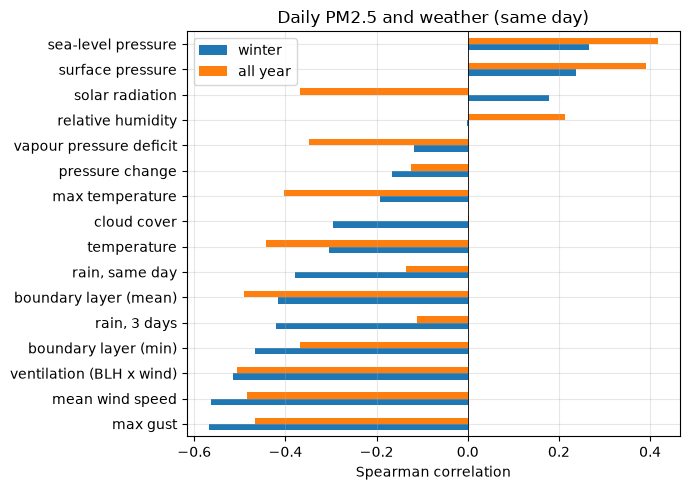

In [11]:
weather_cols = {
    "era5_temp_mean": "temperature",
    "era5_temp_max": "max temperature",
    "era5_rh_mean": "relative humidity",
    "era5_wind_mean": "mean wind speed",
    "era5_gust_max": "max gust",
    "era5_precip": "rain, same day",
    "era5_rain3": "rain, 3 days",
    "era5_pres_mean": "surface pressure",
    "era5_msl_mean": "sea-level pressure",
    "era5_msl_chg": "pressure change",
    "era5_cloud_mean": "cloud cover",
    "era5_ssr_sum": "solar radiation",
    "era5_vpd_mean": "vapour pressure deficit",
    "era5_blh_mean": "boundary layer (mean)",
    "era5_blh_min": "boundary layer (min)",
    "era5_vent_mean": "ventilation (BLH x wind)",
}
win = daily[daily.index.month.isin(WINTER)]
corr = pd.DataFrame(
    {
        "winter": win[["pm25_mean", *weather_cols]].corr(method="spearman")[
            "pm25_mean"
        ],
        "all year": daily[["pm25_mean", *weather_cols]].corr(method="spearman")[
            "pm25_mean"
        ],
    }
).drop("pm25_mean")
corr.index = [weather_cols[c] for c in corr.index]
print("Spearman correlation of the daily PM2.5 mean with same-day weather")
print(corr.round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 5))
corr.sort_values("winter").plot.barh(ax=ax)
ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("Spearman correlation")
ax.set_title("Daily PM2.5 and weather (same day)")
plt.tight_layout()
save(fig, "weather_correlations")

      temperature  wind speed  boundary layer  rain, 3 days
-2 d        -0.09       -0.17           -0.30         -0.37
-1 d        -0.19       -0.32           -0.39         -0.46
+0 d        -0.31       -0.56           -0.42         -0.42
+1 d        -0.37       -0.48           -0.28         -0.33
+2 d        -0.32       -0.30           -0.12         -0.17
+3 d        -0.25       -0.20           -0.10         -0.14

autocorrelation of the winter daily mean at 1, 2, 3, 7 days: [np.float64(0.69), np.float64(0.41), np.float64(0.34), np.float64(0.25)]
saved reports/figures/lagged_correlations.png


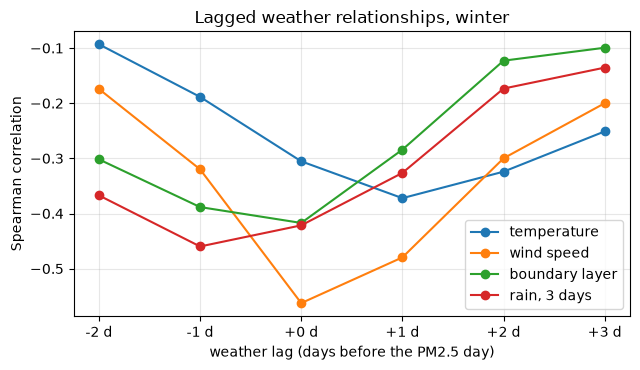

In [12]:
# Lagged relationships (winter days). Weather at lag L is the weather L days before the PM2.5 day;
# a negative L is weather after the PM2.5 day, shown to see how the relationship fades.
lags = [-2, -1, 0, 1, 2, 3]
rows = {}
for col, label in [
    ("era5_temp_mean", "temperature"),
    ("era5_wind_mean", "wind speed"),
    ("era5_blh_mean", "boundary layer"),
    ("era5_rain3", "rain, 3 days"),
]:
    rows[label] = [
        win["pm25_mean"].corr(
            daily[col].shift(lag).reindex(win.index), method="spearman"
        )
        for lag in lags
    ]
auto = [
    win["pm25_mean"].corr(daily["pm25_mean"].shift(lag).reindex(win.index))
    for lag in (1, 2, 3, 7)
]
lag_table = pd.DataFrame(rows, index=[f"{lag:+d} d" for lag in lags])
print(lag_table.round(2).to_string())
print(
    "\nautocorrelation of the winter daily mean at 1, 2, 3, 7 days:",
    [round(a, 2) for a in auto],
)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
lag_table.plot(ax=ax, marker="o")
ax.set_xlabel("weather lag (days before the PM2.5 day)")
ax.set_ylabel("Spearman correlation")
ax.set_title("Lagged weather relationships, winter")
plt.tight_layout()
save(fig, "lagged_correlations")

direction the wind comes from:
    hours  mean_pm25  median_pm25  mean_wind_kmh
N    1620       47.6         38.0            6.8
NE   3178       63.6         52.0            7.4
E    4209       67.4         52.0            7.3
SE   1600       59.3         48.0            7.7
S    1140       47.2         39.0            8.0
SW   1108       52.3         41.0            6.7
W    1549       51.6         40.0            6.3
NW   2299       43.7         33.0            7.2

by wind speed (km/h):
                     size  mean  median
era5_wind_speed_10m                    
(0, 3]               1649  67.7    56.0
(3, 6]               5650  69.3    56.0
(6, 10]              6176  53.7    41.0
(10, 15]             2580  37.3    28.0
(15, 100]             645  29.2    22.0

direction, wind speed 3 to 10 km/h only:
    size  mean
N   1252  49.4
NE  2180  71.2
E   2885  75.0
SE  1081  65.7
S    703  51.5
SW   754  52.4
W   1210  52.5
NW  1761  45.2


saved reports/figures/wind_direction_and_speed.png


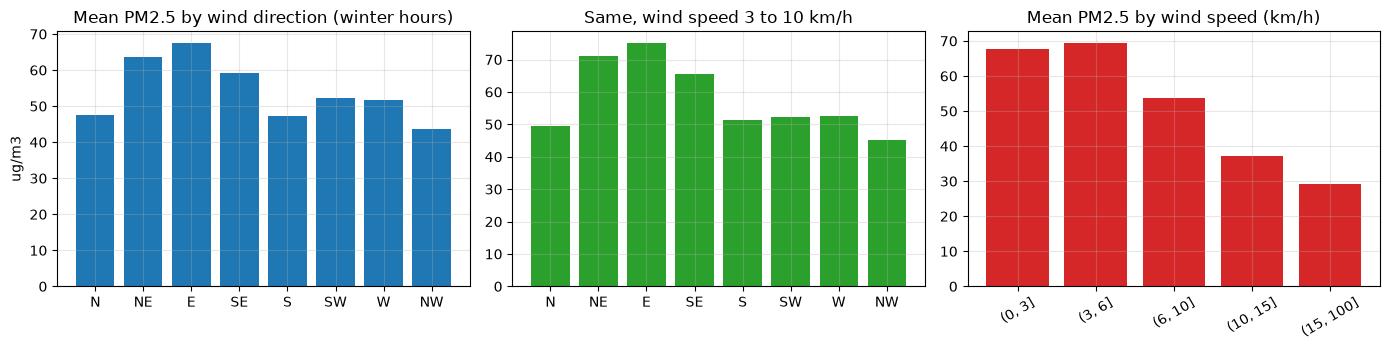

In [13]:
# Wind direction (hourly, winter). ERA5 wind is for the grid cell, not the station.
hw = hourly[hourly.index.month.isin(WINTER)].dropna(subset=["pm25"])
sector = ((hw["era5_wind_direction_10m"] + 22.5) // 45 % 8).astype(int)
names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
by_sector = hw.groupby(sector).agg(
    hours=("pm25", "size"),
    mean_pm25=("pm25", "mean"),
    median_pm25=("pm25", "median"),
    mean_wind_kmh=("era5_wind_speed_10m", "mean"),
)
by_sector.index = names
print("direction the wind comes from:")
print(by_sector.round(1).to_string())
speed_bins = pd.cut(hw["era5_wind_speed_10m"], [0, 3, 6, 10, 15, 100])
by_speed = hw.groupby(speed_bins, observed=True)["pm25"].agg(["size", "mean", "median"])
print("\nby wind speed (km/h):")
print(by_speed.round(1).to_string())
# Direction effect at similar wind speeds: the 3 to 10 km/h hours only.
mid = hw[(hw["era5_wind_speed_10m"] > 3) & (hw["era5_wind_speed_10m"] <= 10)]
mid_sector = ((mid["era5_wind_direction_10m"] + 22.5) // 45 % 8).astype(int)
by_mid = mid.groupby(mid_sector)["pm25"].agg(["size", "mean"])
by_mid.index = names
print("\ndirection, wind speed 3 to 10 km/h only:")
print(by_mid.round(1).to_string())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].bar(names, by_sector["mean_pm25"])
axes[0].set_title("Mean PM2.5 by wind direction (winter hours)")
axes[0].set_ylabel("ug/m3")
axes[1].bar(names, by_mid["mean"], color="tab:green")
axes[1].set_title("Same, wind speed 3 to 10 km/h")
axes[2].bar([str(i) for i in by_speed.index], by_speed["mean"], color="tab:red")
axes[2].set_title("Mean PM2.5 by wind speed (km/h)")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
save(fig, "wind_direction_and_speed")

boundary layer height, mean (m)
            days  mean PM2.5  median PM2.5
13 to 67     127        79.0          71.5
67 to 105    126        58.8          54.2
105 to 153   126        59.6          53.2
153 to 218   126        47.9          40.3
218 to 525   127        36.8          32.6

ventilation (m x km/h)
              days  mean PM2.5  median PM2.5
61 to 404      127        84.4          76.2
404 to 638     126        61.3          56.6
638 to 1028    126        54.0          47.3
1028 to 1725   126        46.7          40.1
1725 to 8540   127        35.5          29.1

daily temperature range (C)
              days  mean PM2.5  median PM2.5
1.9 to 6.5     138        40.6          35.7
6.5 to 8.7     142        54.4          46.7
8.7 to 10.6    135        61.1          55.2
10.6 to 12.7   139        65.9          50.4
12.7 to 19.2   136        60.9          51.3

sea-level pressure (hPa)
              days  mean PM2.5  median PM2.5
1005 to 1018   138        39.3          35.0
1

saved reports/figures/stagnation_proxies.png


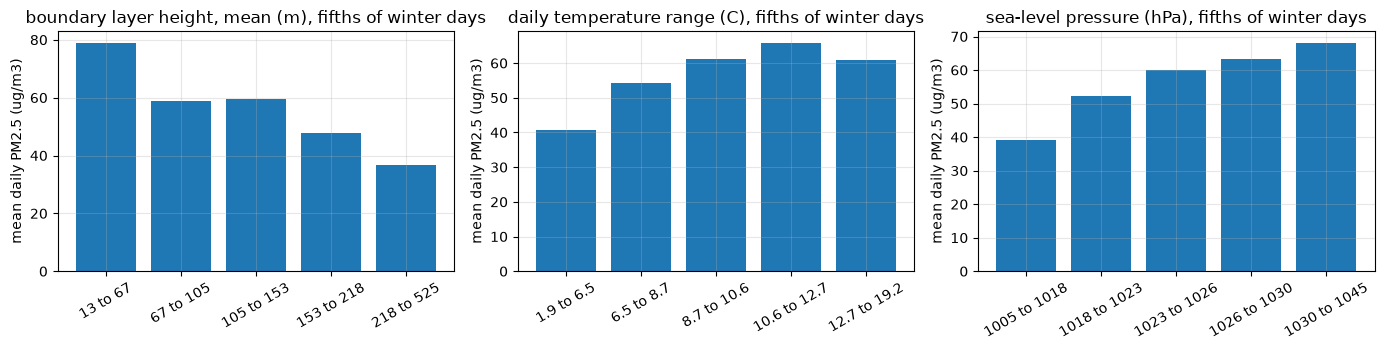

In [14]:
# Stagnation proxies. There is no direct inversion measurement here: ERA5 boundary layer height
# (missing 2024-01-01 to 2024-06-30), the daily temperature range, and the pressure level.
w = win.copy()
w["temp_range"] = w["era5_temp_max"] - w["era5_temp_min"]
rows = []
for col, label in [
    ("era5_blh_mean", "boundary layer height, mean (m)"),
    ("era5_vent_mean", "ventilation (m x km/h)"),
    ("temp_range", "daily temperature range (C)"),
    ("era5_msl_mean", "sea-level pressure (hPa)"),
    ("era5_wind_mean", "mean wind (km/h)"),
]:
    data = w[["pm25_mean", col]].dropna()
    bins = pd.qcut(data[col], 5)
    g = data.groupby(bins, observed=True)["pm25_mean"].agg(["count", "mean", "median"])
    g.index = [
        f"{i.left:.0f} to {i.right:.0f}"
        if abs(i.right) >= 20
        else f"{i.left:.1f} to {i.right:.1f}"
        for i in g.index
    ]
    g.columns = ["days", "mean PM2.5", "median PM2.5"]
    rows.append((label, g))
for label, g in rows:
    print(label)
    print(g.round(1).to_string())
    print()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (label, g) in zip(axes, [rows[0], rows[2], rows[3]], strict=True):
    ax.bar(range(5), g["mean PM2.5"], tick_label=g.index)
    ax.set_title(label + ", fifths of winter days")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylabel("mean daily PM2.5 (ug/m3)")
plt.tight_layout()
save(fig, "stagnation_proxies")

## 4. Spatial patterns (2.3.4)

Only one station has usable multi-year data (the US Diplomatic Post), so the project cannot say anything about spatial variation across the city. There is one chance for a sanity check: the TIIAME station in the Mendeley dataset (about 6 km from the US station, light-scattering sensor, February to September 2024) overlaps with the US series. The comparison below uses daily means over days with at least 18 observed hours at each station.

distance between the stations: about 5.4 km
overlapping days: 185 (2024-02-27 to 2024-09-11)
mean daily PM2.5: {'TIIAME': 7.3, 'US Embassy': 18.2}
correlation: Pearson 0.82, Spearman 0.77
median ratio TIIAME / US Embassy: 0.41


saved reports/figures/two_station_comparison.png


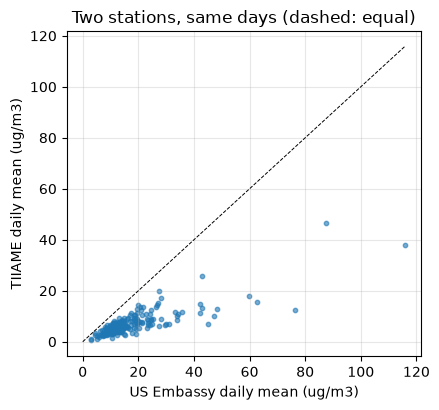

In [15]:
m = pd.read_csv(ROOT / "data" / "raw" / "mendeley_tashkent" / "all_sensor.csv")
m["t"] = pd.to_datetime(
    m["Date"] + " " + m["Time"], format="%m/%d/%Y %H:%M:%S"
)  # local time
g = m.groupby(m["t"].dt.floor("D"))["PM25/ug/m3"].agg(["mean", "count"])
g = g[g["count"] >= 36]  # at least 18 hours at 30-minute resolution
both = pd.concat(
    [g["mean"].rename("TIIAME"), pm.rename("US Embassy")], axis=1, sort=True
).dropna()
dist_km = np.hypot(
    (41.322005 - 41.3672) * 111.0,
    (69.295986 - 69.2725) * 111.0 * np.cos(np.radians(41.3)),
)
print(f"distance between the stations: about {dist_km:.1f} km")
print(
    f"overlapping days: {len(both)} ({both.index.min().date()} to {both.index.max().date()})"
)
print("mean daily PM2.5:", both.mean().round(1).to_dict())
print(
    f"correlation: Pearson {both.corr().iloc[0, 1]:.2f}, Spearman {both.corr(method='spearman').iloc[0, 1]:.2f}"
)
print(
    f"median ratio TIIAME / US Embassy: {(both['TIIAME'] / both['US Embassy']).median():.2f}"
)
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.scatter(both["US Embassy"], both["TIIAME"], s=10, alpha=0.6)
top = max(both.max())
ax.plot([0, top], [0, top], "k--", lw=0.7)
ax.set_xlabel("US Embassy daily mean (ug/m3)")
ax.set_ylabel("TIIAME daily mean (ug/m3)")
ax.set_title("Two stations, same days (dashed: equal)")
plt.tight_layout()
save(fig, "two_station_comparison")

The two stations move together from day to day but at different levels, with the TIIAME sensor reading much lower. The data cannot separate a real difference between two places 6 km apart from a difference between a reference-grade monitor and a low-cost-style light-scattering sensor, and the overlap is the warm season only. That is one reason the project does not claim any spatial result.

## 5. Findings (2.3.5)

All numbers come from the cells above (US Diplomatic Post station, 1,823 days with a daily mean, 44,077 valid hours). They describe associations in observed data, for one station, and each is based on the days available (thin months are visible in the count table of section 1.1).

**Seasonal and daily patterns (2.3.1)**
- PM2.5 follows a strong seasonal cycle. Monthly mean daily values are highest in December (66.4 ug/m3), November (58.9) and January (58.1), and lowest in May (21.4). In December 55% of days have a daily mean of at least 55.5 ug/m3, against 1% in April and none in May.
- In winter the day has a clear shape: the hourly mean is about 62 at night (00:00 to 06:00), 45 in the afternoon (12:00 to 16:00) and 66 in the evening (20:00 to 23:59). In summer the shape is much flatter (25, 23 and 33).
- There is no clear weekday pattern. Daily means vary by at most about 3 ug/m3 across weekdays over all days (39.0 to 41.7) and about 5 in winter (54.0 to 58.7), with no consistent weekend difference. A formal test belongs to notebook 04.
- The winters differ. The mean daily value in November to February was 50.8 in 2019-20, 53.6 in 2020-21, 53.5 in 2021-22, 67.8 in 2022-23, 68.6 in 2023-24 and 61.5 in 2024-25 (2018-19 is partial, 78 days, mean 39.3). The share of winter days at or above 55.5 rose from 29% to 55% over the same winters before falling to 47%. The data cannot say whether this is a trend, because the winters differ in weather and in how many days are observed (82 to 115 days).

**Distribution and extremes (2.3.2)**
- Daily means are skewed to the right (skewness 2.8) but close to symmetric on a log scale (0.08), so a log-normal shape is a reasonable description. Hourly values are more extreme (skewness 4.5, maximum 978).
- 91% of days exceed the WHO 24-hour guideline of 15 ug/m3 (98% in winter). 42% exceed 35.5, 20% exceed 55.5, 4.7% exceed 100 and 1.0% exceed 150.5. In winter the shares are 69%, 40%, 12% and 2.6%.
- There are 86 days at or above 100 ug/m3, in 44 runs; 22 runs last two days or more and the longest lasts 6 days (from 2023-01-16). Nearly all are in November to February. One 3-day run in September 2024 (mean temperature 17 C) does not fit the winter pattern, and its cause is unknown.
- During the episodes of two days or more, mean wind is lower than the winter average in most (3.8 to 7.0 km/h against 7.2 km/h), and in the December and January episodes of 2022-23 the boundary layer is shallow (24 to 49 m against a winter average of 147 m). Not all episodes fit: some have high boundary layers (234 m in December 2023) and stronger wind (8.8 km/h). Episodes are not all the same kind of event.

**Weather relationships (2.3.3)**
- In winter the daily mean is lower when it is windy (Spearman -0.56 with mean wind, -0.57 with the maximum gust), when the ventilation index (boundary layer height times wind) is high (-0.51), when the boundary layer is deep (-0.42 mean, -0.47 minimum) and when it has rained recently (-0.42 for 3 days). It is higher under high sea-level pressure (+0.27) and shows almost no relation with humidity (0.00 in winter, +0.21 over the year).
- By fifths of winter days, the lowest fifth of boundary layer heights (13 to 67 m) has a mean of 79.0 ug/m3 against 36.8 in the highest fifth, wind (2.1 to 5.1 km/h against 9.1 to 16.8) 85.5 against 35.2, and sea-level pressure 39.3 (below 1018 hPa) against 68.1 (above 1030 hPa). Days with a mid-sized temperature range (8.7 to 12.7 C) have the highest means (61 to 66), which is consistent with clear, calm, cold nights.
- The relationship with wind is strongest on the same day (-0.56) and fades with days (about -0.2 after three days). Temperature is most strongly related with the day before (-0.37). Rain on the following day relates as strongly as rain on the day itself (-0.46 and -0.42), consistent with weather systems that bring rain also clearing the air, and not evidence that rain is cause or effect. Winter daily means are persistent: autocorrelation 0.69 at one day, 0.41 at two, 0.34 at three and 0.25 at seven.
- Wind direction matters at similar wind speeds. Winter hours with wind from the east or north-east average 67.4 and 63.6 ug/m3 against 43.7 from the north-west, and when only hours with wind of 3 to 10 km/h are compared the gap remains (75.0 from the east and 71.2 from the north-east against 45.2 from the north-west). The wind is the ERA5 grid-cell wind, so this shows where the air comes from in the model, and it does not identify any source.
- Boundary layer height and the other proxies come from reanalysis. They are not direct measurements of temperature inversions, which the available data does not include.

**Spatial patterns (2.3.4)**
- Only one station has multi-year data, so no spatial claims are supported. Over the 185 overlapping days (2024-02-27 to 2024-09-11), the TIIAME station (5.4 km away) correlates with the US station (Pearson 0.82, Spearman 0.77) but reads about 40% as high (mean 7.3 against 18.2 ug/m3). The data cannot separate a real difference between the places from an instrument difference, and the overlap is the warm season.

**What this implies for modelling (to be tested, not concluded here)**
- Weather, especially wind and boundary-layer variables, and the day-to-day persistence are the obvious predictors, and winter needs separate attention.
- Episodes are few (22 runs of two days or more), so any evaluation of high-pollution forecasts rests on a small number of events.
- The winter-to-winter differences mean results should be reported per winter.

**Open questions for the statistical analysis (notebook 04)**
- Are the winter differences larger than expected from sampling? How much of the wind-direction effect remains after allowing for wind speed and season?
- Do the lagged relationships and the weekday figures survive tests that account for autocorrelation?
